In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv(r"machine_sensor_data.csv")
df.head()

,operating_hours,temperature_c,vibration_mm_s,pressure_bar,oil_quality_score,noise_db,coolant_level_pct,maintenance_required
0,1162,78.8,3.37,6.57,98.1,67.1,76.4,No
1,9310,72.2,7.92,5.56,61.6,74.3,89.5,Yes
2,7890,76.2,3.79,4.93,79.1,60.0,91.7,No
3,5323,52.3,1.76,6.80,65.9,60.7,88.8,No
4,5253,62.3,6.62,7.68,74.5,68.4,76.4,No


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   operating_hours       1200 non-null   int64  
 1   temperature_c         1200 non-null   float64
 2   vibration_mm_s        1200 non-null   float64
 3   pressure_bar          1200 non-null   float64
 4   oil_quality_score     1200 non-null   float64
 5   noise_db              1200 non-null   float64
 6   coolant_level_pct     1200 non-null   float64
 7   maintenance_required  1200 non-null   str    
dtypes: float64(6), int64(1), str(1)
memory usage: 77.9 KB


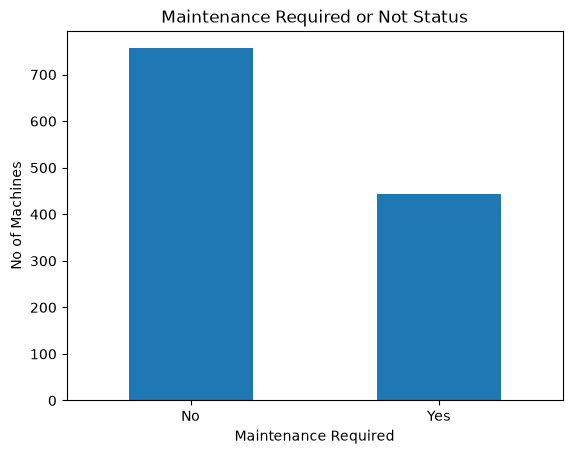

In [5]:

# Visualize Target Labels
df["maintenance_required"].value_counts().plot(kind="bar")
plt.title("Maintenance Required or Not Status")
plt.xlabel("Maintenance Required")
plt.ylabel("No of Machines")
plt.xticks(rotation=0)
plt.show()


In [9]:
X = df.drop(columns = ["maintenance_required"])
y = df["maintenance_required"]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(X_train.shape)
print(X_test.shape)

(960, 7)
(240, 7)


In [12]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

svm_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['operating_hours','temperature_c','vibration_mm_s',..., 'oil_quality_score','noise_db','coolant_level_pct']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [15]:

y_pred = svm_model.predict(X_test)

prediction_table = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": y_pred
})

prediction_table.head(10)


,Actual,Predicted
0,No,No
1,No,No
2,No,No
3,Yes,No
4,No,No
5,No,No
6,No,Yes
7,No,No
8,No,No
9,Yes,No


In [17]:
acc = accuracy_score(y_test , y_pred)
acc

0.8208333333333333

In [20]:
cm = confusion_matrix(y_test, y_pred, labels = ["No", "Yes"])
pd.DataFrame(
    cm,
    index = ["Actual Rejected", "Actual Approvals"],
    columns = ["Predicted Rejection", "Predicted Approvals"]
)

,Predicted Rejection,Predicted Approvals
Actual Rejected,134,19
Actual Approvals,24,63


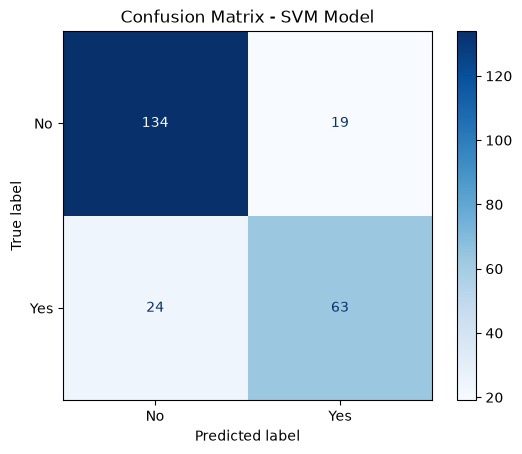

In [25]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - SVM Model")
plt.show()

In [26]:
new_data = pd.DataFrame({
    "operating_hours": [6000],
    "temperature_c": [75.0],
    "vibration_mm_s": [4.0],
    "pressure_bar": [5.0],
    "oil_quality_score": [70.0],
    "noise_db": [78.0],
    "coolant_level_pct": [60.0]
})

# Predict maintenance requirement
prediction = svm_model.predict(new_data)

# Display the input data and prediction
new_data["maintenance_required"] = prediction

new_data

,operating_hours,temperature_c,vibration_mm_s,pressure_bar,oil_quality_score,noise_db,coolant_level_pct,maintenance_required
0,6000,75.0,4.0,5.0,70.0,78.0,60.0,Yes
